# Final Model Training and Test Evaluation

## Objective

Train the selected XGBoost model using the complete 80% training pool and evaluate its generalisation performance on the untouched 20% test set.

## Selected Configuration

- Model: XGBoost
- Target: Predict whether the next eligible main question is answered correctly.
- Risk class: Incorrect answer (`correct = 0`)
- Target recall: 75%
- Classification threshold: 0.2880
- Random state: 42

The model and threshold were selected using five-fold cross-validation on the training pool.
The test set will remain untouched until final evaluation.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
import joblib

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    log_loss,
    brier_score_loss,
    confusion_matrix,
    classification_report,
    roc_curve,
    precision_recall_curve
)

from xgboost import XGBClassifier

# Final configuration
FINAL_MODEL = "XGBoost"
FINAL_THRESHOLD = 0.2880
TARGET_RECALL = 0.75
RANDOM_STATE = 42

# Feature definitions
numeric_features = [
    "overall_smoothed_accuracy",
    "weighted_same_skill_smoothed_accuracy",
    "log_weighted_same_skill_previous_interactions",
    "weighted_other_skill_smoothed_accuracy",
    "question_smoothed_accuracy",
    "log_question_previous_interactions"
]

categorical_features = ["answer_type"]

feature_columns = numeric_features + categorical_features
target_column = "correct"

key_columns = ["user_id", "order_id"]

print("Final model configuration loaded.")

Final model configuration loaded.


In [2]:
combined_dir = Path(
    "../../../data/processed/engineered_features/combined_model"
)

print("Directory:", combined_dir.resolve())

for path in sorted(combined_dir.rglob("*.csv")):
    print(path.relative_to(combined_dir))

Directory: C:\Users\rajur\OneDrive\Desktop\next-move-ai\data\processed\engineered_features\combined_model
fold_1_train.csv
fold_1_validation.csv
fold_2_train.csv
fold_2_validation.csv
fold_3_train.csv
fold_3_validation.csv
fold_4_train.csv
fold_4_validation.csv
fold_5_train.csv
fold_5_validation.csv


In [3]:
validation_datasets = []

for fold_number in range(1, 6):

    file_path = combined_dir / f"fold_{fold_number}_validation.csv"

    fold_data = pd.read_csv(file_path)

    print(f"Fold {fold_number}: {fold_data.shape}")

    validation_datasets.append(fold_data)

# Combine the five non-overlapping validation partitions
final_train_data = pd.concat(
    validation_datasets,
    ignore_index=True
)

print("\nCombined training-pool shape:", final_train_data.shape)

# Verify interaction uniqueness
print(
    "Duplicate interactions:",
    final_train_data.duplicated(key_columns).sum()
)

print(
    "Unique students:",
    final_train_data["user_id"].nunique()
)

print(
    "Missing values:",
    final_train_data.isna().sum().sum()
)

Fold 1: (42659, 10)
Fold 2: (43710, 10)
Fold 3: (49797, 10)
Fold 4: (41672, 10)
Fold 5: (42145, 10)

Combined training-pool shape: (219983, 10)
Duplicate interactions: 0
Unique students: 3373
Missing values: 0


In [4]:
engineered_dir = Path(
    "../../../data/processed/engineered_features"
)

for path in sorted(engineered_dir.iterdir()):
    if path.is_dir():
        print(path.name)

combined_model
group_1_overall_history
group_2_same_skill_history
group_3_other_skill_history
group_4_question_difficulty


In [5]:
for group_dir in sorted(engineered_dir.iterdir()):

    if group_dir.is_dir() and group_dir.name.startswith("group_"):

        print(f"\n{'='*65}")
        print(group_dir.name)
        print("="*65)

        for path in sorted(group_dir.rglob("*")):

            if path.is_file():
                print(path.relative_to(engineered_dir))


group_1_overall_history
group_1_overall_history\v1.1\fold_1_train.csv
group_1_overall_history\v1.1\fold_1_validation.csv
group_1_overall_history\v1.1\fold_2_train.csv
group_1_overall_history\v1.1\fold_2_validation.csv
group_1_overall_history\v1.1\fold_3_train.csv
group_1_overall_history\v1.1\fold_3_validation.csv
group_1_overall_history\v1.1\fold_4_train.csv
group_1_overall_history\v1.1\fold_4_validation.csv
group_1_overall_history\v1.1\fold_5_train.csv
group_1_overall_history\v1.1\fold_5_validation.csv
group_1_overall_history\v1.2\fold_1_train.csv
group_1_overall_history\v1.2\fold_1_validation.csv
group_1_overall_history\v1.2\fold_2_train.csv
group_1_overall_history\v1.2\fold_2_validation.csv
group_1_overall_history\v1.2\fold_3_train.csv
group_1_overall_history\v1.2\fold_3_validation.csv
group_1_overall_history\v1.2\fold_4_train.csv
group_1_overall_history\v1.2\fold_4_validation.csv
group_1_overall_history\v1.2\fold_5_train.csv
group_1_overall_history\v1.2\fold_5_validation.csv

grou

In [6]:
final_train_path = combined_dir / "final_training_pool.csv"

final_train_data.to_csv(final_train_path, index=False)

print("Saved:", final_train_path)
print("Shape:", final_train_data.shape)

Saved: ..\..\..\data\processed\engineered_features\combined_model\final_training_pool.csv
Shape: (219983, 10)


In [7]:
for group_dir in sorted(engineered_dir.iterdir()):

    if group_dir.is_dir() and group_dir.name.startswith("group_"):

        print(f"\n{'='*60}")
        print(group_dir.name)
        print("="*60)

        for path in sorted(group_dir.rglob("*")):
            if path.is_file():
                print(path.relative_to(engineered_dir))


group_1_overall_history
group_1_overall_history\v1.1\fold_1_train.csv
group_1_overall_history\v1.1\fold_1_validation.csv
group_1_overall_history\v1.1\fold_2_train.csv
group_1_overall_history\v1.1\fold_2_validation.csv
group_1_overall_history\v1.1\fold_3_train.csv
group_1_overall_history\v1.1\fold_3_validation.csv
group_1_overall_history\v1.1\fold_4_train.csv
group_1_overall_history\v1.1\fold_4_validation.csv
group_1_overall_history\v1.1\fold_5_train.csv
group_1_overall_history\v1.1\fold_5_validation.csv
group_1_overall_history\v1.2\fold_1_train.csv
group_1_overall_history\v1.2\fold_1_validation.csv
group_1_overall_history\v1.2\fold_2_train.csv
group_1_overall_history\v1.2\fold_2_validation.csv
group_1_overall_history\v1.2\fold_3_train.csv
group_1_overall_history\v1.2\fold_3_validation.csv
group_1_overall_history\v1.2\fold_4_train.csv
group_1_overall_history\v1.2\fold_4_validation.csv
group_1_overall_history\v1.2\fold_5_train.csv
group_1_overall_history\v1.2\fold_5_validation.csv

grou

In [8]:
processed_dir = Path("../../../data/processed")

print("Available processed files:")

for path in sorted(processed_dir.rglob("*.csv")):
    print(path.relative_to(processed_dir))

Available processed files:
engineered_features\combined_model\final_training_pool.csv
engineered_features\combined_model\fold_1_train.csv
engineered_features\combined_model\fold_1_validation.csv
engineered_features\combined_model\fold_2_train.csv
engineered_features\combined_model\fold_2_validation.csv
engineered_features\combined_model\fold_3_train.csv
engineered_features\combined_model\fold_3_validation.csv
engineered_features\combined_model\fold_4_train.csv
engineered_features\combined_model\fold_4_validation.csv
engineered_features\combined_model\fold_5_train.csv
engineered_features\combined_model\fold_5_validation.csv
engineered_features\group_1_overall_history\v1.1\fold_1_train.csv
engineered_features\group_1_overall_history\v1.1\fold_1_validation.csv
engineered_features\group_1_overall_history\v1.1\fold_2_train.csv
engineered_features\group_1_overall_history\v1.1\fold_2_validation.csv
engineered_features\group_1_overall_history\v1.1\fold_3_train.csv
engineered_features\group_1_o

In [9]:
required_files = [
    "main_questions_cleaned.csv",
    "split_assignments.csv"
]

for filename in required_files:

    matches = list(processed_dir.rglob(filename))

    print(f"\n{filename}")

    if matches:
        for path in matches:
            print("Found:", path.resolve())
    else:
        print("NOT FOUND")


main_questions_cleaned.csv
Found: C:\Users\rajur\OneDrive\Desktop\next-move-ai\data\processed\main_questions_cleaned.csv

split_assignments.csv
Found: C:\Users\rajur\OneDrive\Desktop\next-move-ai\data\processed\split_assignments.csv


In [11]:
from pathlib import Path
import pandas as pd

# Define processed data directory
processed_dir = Path("../../../data/processed")

# Define file paths
cleaned_path = processed_dir / "main_questions_cleaned.csv"
split_path = processed_dir / "split_assignments.csv"

# Load datasets
cleaned_data = pd.read_csv(cleaned_path)
split_assignments = pd.read_csv(split_path)

# Display information
print("CLEANED DATASET")
print("Shape:", cleaned_data.shape)
print("Columns:", cleaned_data.columns.tolist())

print("\nSPLIT ASSIGNMENTS")
print("Shape:", split_assignments.shape)
print("Columns:", split_assignments.columns.tolist())

print("\nPartition distribution:")
display(split_assignments["partition"].value_counts())

print("\nFirst five cleaned records:")
display(cleaned_data.head())

CLEANED DATASET
Shape: (275458, 8)
Columns: ['user_id', 'order_id', 'problem_id', 'correct', 'skill_id', 'skill_set', 'attempt_count', 'answer_type']

SPLIT ASSIGNMENTS
Shape: (4217, 3)
Columns: ['user_id', 'partition', 'validation_fold']

Partition distribution:


partition
train_pool    3373
test           844
Name: count, dtype: int64


First five cleaned records:


,user_id,order_id,problem_id,correct,skill_id,skill_set,attempt_count,answer_type
0,14,21617623,93383,0,2_37_70,"{'70', '2', '37'}",1,algebra
1,14,21617632,93407,1,2_37_70,"{'70', '2', '37'}",1,algebra
2,14,21617641,93400,0,2_37_70,"{'70', '2', '37'}",1,algebra
3,14,21617650,93419,0,2_37_70,"{'70', '2', '37'}",1,algebra
4,14,21617659,93420,0,2_37_70,"{'70', '2', '37'}",1,algebra


In [12]:
# Attach each student's partition to their interactions
data_with_partition = cleaned_data.merge(
    split_assignments[["user_id", "partition"]],
    on="user_id",
    how="left",
    validate="many_to_one"
)

# Verify the merge
print("Shape:", data_with_partition.shape)

print("\nMissing partition assignments:",
      data_with_partition["partition"].isna().sum())

print("\nInteraction distribution:")
display(data_with_partition["partition"].value_counts())

print("\nUnique students per partition:")
display(
    data_with_partition.groupby("partition")["user_id"].nunique()
)

print("\nDuplicate interaction keys:",
      data_with_partition.duplicated(["user_id", "order_id"]).sum())

Shape: (275458, 9)

Missing partition assignments: 0

Interaction distribution:


partition
train_pool    219983
test           55475
Name: count, dtype: int64


Unique students per partition:


partition
test           844
train_pool    3373
Name: user_id, dtype: int64


Duplicate interaction keys: 0


In [13]:
# Sort interactions chronologically
data_with_partition = data_with_partition.sort_values(
    ["user_id", "order_id"]
).reset_index(drop=True)

# Verify ordering
print("Is order_id increasing within every student?")

chronological_check = (
    data_with_partition.groupby("user_id")["order_id"]
    .apply(lambda x: x.is_monotonic_increasing)
)

print("All students correctly ordered:", chronological_check.all())

# Inspect one student's interaction history
sample_user = data_with_partition["user_id"].iloc[0]

display(
    data_with_partition[
        data_with_partition["user_id"] == sample_user
    ].head(10)
)

Is order_id increasing within every student?
All students correctly ordered: True


,user_id,order_id,problem_id,correct,skill_id,skill_set,attempt_count,answer_type,partition
0,14,21617623,93383,0,2_37_70,"{'70', '2', '37'}",1,algebra,train_pool
1,14,21617632,93407,1,2_37_70,"{'70', '2', '37'}",1,algebra,train_pool
2,14,21617641,93400,0,2_37_70,"{'70', '2', '37'}",1,algebra,train_pool
3,14,21617650,93419,0,2_37_70,"{'70', '2', '37'}",1,algebra,train_pool
4,14,21617659,93420,0,2_37_70,"{'70', '2', '37'}",1,algebra,train_pool
5,14,21617667,93415,0,2_37_70,"{'70', '2', '37'}",1,algebra,train_pool
6,14,21617675,93423,0,2_37_48_77,"{'2', '48', '37', '77'}",1,algebra,train_pool
7,14,21617692,57695,0,2_48_79,"{'2', '48', '79'}",0,algebra,train_pool
8,14,21617731,58596,1,2_37_48,"{'2', '48', '37'}",1,algebra,train_pool
9,14,21617749,57647,0,2_48_79,"{'2', '48', '79'}",0,algebra,train_pool


In [14]:
from pathlib import Path

# Locate the project root
project_root = Path("../../../").resolve()

print("Project root:", project_root)

# Find notebooks related to feature engineering
notebooks = list(project_root.rglob("*.ipynb"))

feature_notebooks = [
    path for path in notebooks
    if any(
        keyword in str(path).lower()
        for keyword in ["feature", "history", "difficulty"]
    )
]

print("\nRelevant notebooks found:")

for i, path in enumerate(feature_notebooks, 1):
    print(f"{i}. {path.relative_to(project_root)}")

Project root: C:\Users\rajur\OneDrive\Desktop\next-move-ai

Relevant notebooks found:
1. notebooks\models\01_overall_student_history\v1.1_smoothed_binary_accuracy.ipynb
2. notebooks\models\01_overall_student_history\v1.2_accuracy_plus_experience.ipynb
3. notebooks\models\02_same_skill_student_history\00_feature_engineering.ipynb
4. notebooks\models\02_same_skill_student_history\v2.1_binary_same_skill_accuracy.ipynb
5. notebooks\models\02_same_skill_student_history\v2.2_fractional_same_skill_accuracy.ipynb
6. notebooks\models\02_same_skill_student_history\v2.3_binary_accuracy_plus_experience.ipynb
7. notebooks\models\02_same_skill_student_history\v2.4_fractional_accuracy_plus_experience.ipynb
8. notebooks\models\03_other_skill_student_history\00_feature_engineering.ipynb
9. notebooks\models\03_other_skill_student_history\v3.1_binary_other_skill_accuracy.ipynb
10. notebooks\models\03_other_skill_student_history\v3.2_fractional_other_skill_accuracy.ipynb
11. notebooks\models\03_other_skil

In [15]:
import json
from pathlib import Path

notebook_paths = {
    "G1 - Overall history (V1.1)":
        project_root / "notebooks/models/01_overall_student_history/v1.1_smoothed_binary_accuracy.ipynb",

    "G2 - Same-skill history (V2.4)":
        project_root / "notebooks/models/02_same_skill_student_history/v2.4_fractional_accuracy_plus_experience.ipynb",

    "G3 - Other-skill history (V3.2)":
        project_root / "notebooks/models/03_other_skill_student_history/v3.2_fractional_other_skill_accuracy.ipynb",

    "G4 - Question difficulty (V4.3)":
        project_root / "notebooks/models/04_question_difficulty/v4.3_accuracy_exposure_question_type.ipynb"
}

for notebook_name, notebook_path in notebook_paths.items():

    print("\n" + "=" * 90)
    print(notebook_name)
    print("=" * 90)

    with open(notebook_path, "r", encoding="utf-8") as file:
        notebook = json.load(file)

    for i, cell in enumerate(notebook["cells"]):

        if cell["cell_type"] == "code":
            source = "".join(cell["source"])

            if source.strip():
                print(f"\n--- Code Cell {i} ---")
                print(source)


G1 - Overall history (V1.1)

--- Code Cell 0 ---
import pandas as pd
import numpy as np
import sys
from pathlib import Path

project_root = Path.cwd().parents[2]
sys.path.insert(0, str(project_root))

print("Project root:", project_root)

--- Code Cell 1 ---
import pandas as pd
import numpy as np
from pathlib import Path

project_root = Path.cwd().parents[2]

print("Project root:", project_root)
# Load the saved student assignments
split_path = project_root  / "data" / "processed" / "split_assignments.csv"

split_assignments = pd.read_csv(split_path)

# Keep only training-pool students
train_assignments = split_assignments[
    split_assignments["partition"] == "train_pool"
].copy()

# Convert fold numbers to integers
train_assignments["validation_fold"] = (
    train_assignments["validation_fold"].astype(int)
)

# Extract training student IDs
train_student_ids = set(train_assignments["user_id"])

print("Training students:", len(train_student_ids))
print("\nStudents assigned to each v

In [17]:
import sys
from pathlib import Path

# Locate the project root by finding the folder containing src/
current_path = Path.cwd()

project_root = next(
    (
        path for path in [current_path, *current_path.parents]
        if (path / "src").is_dir()
    ),
    None
)

if project_root is None:
    raise FileNotFoundError("Could not locate the project root containing src/")

# Add project root to Python's import search path
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

print("Project root:", project_root)
print("src directory exists:", (project_root / "src").is_dir())

Project root: c:\Users\rajur\OneDrive\Desktop\next-move-ai
src directory exists: True


In [18]:
import inspect
import src.feature_engineering as fe

print("Feature engineering module imported successfully!")

for name, function in inspect.getmembers(fe, inspect.isfunction):
    if "history" in name.lower() or "question" in name.lower():
        print(name)

Feature engineering module imported successfully!
_build_other_skill_history_index
_query_total_history
add_fractional_same_skill_history_features
add_other_skill_history_features
add_overall_history_features
add_question_difficulty_features
add_same_skill_history_features


In [19]:
import inspect

selected_functions = [
    "add_overall_history_features",
    "add_fractional_same_skill_history_features",
    "add_other_skill_history_features",
    "add_question_difficulty_features"
]

for function_name in selected_functions:
    function = getattr(fe, function_name)

    print("\n" + "=" * 90)
    print(function_name)
    print("=" * 90)

    print(inspect.getsource(function))


add_overall_history_features
def add_overall_history_features(data, alpha=10, prior_data=None):
    """
    Construct chronological overall student-history features.

    Features:
    1. Smoothed historical accuracy
    2. Log-transformed previous interaction count

    The global smoothing prior uses only eligible interactions
    with a smaller order_id.
    """

    df = data.copy()

    # Ensure chronological order within each student
    df = df.sort_values(
        ["user_id", "order_id"]
    ).reset_index(drop=True)

    # 1. Count previous interactions of the same student
    df["previous_interactions"] = (
        df.groupby("user_id").cumcount()
    )

    # 2. Count previous correct interactions of the same student
    df["previous_correct"] = (
        df.groupby("user_id")["correct"]
          .transform(
              lambda s: s.cumsum().shift(1, fill_value=0)
          )
    )

    # 3. Select the data allowed to contribute to the global prior
    if prior_data is Non

In [20]:
import inspect

helper_functions = [
    "_build_fractional_skill_index",
    "_query_fractional_skill_index",
    "_normalise_other_skill_set",
    "_build_other_skill_history_index",
    "_query_total_history",
    "_query_binary_skill_index"
]

for function_name in helper_functions:
    function = getattr(fe, function_name)

    print("\n" + "=" * 80)
    print(function_name)
    print("=" * 80)

    print(inspect.getsource(function))


_build_fractional_skill_index
def _build_fractional_skill_index(data):
    """
    Build chronological cumulative weighted-history indexes.

    Each previous question distributes its contribution equally
    across its own skills: 1 / number_of_previous_question_skills.
    """

    skill_entries = {}

    for order_id, skill_set, correct in zip(
        data["order_id"],
        data["skill_set"],
        data["correct"]
    ):

        if not skill_set:
            continue

        weight = 1.0 / len(skill_set)

        for skill in skill_set:

            if skill not in skill_entries:
                skill_entries[skill] = []

            skill_entries[skill].append(
                (order_id, weight, weight * correct)
            )

    skill_index = {}

    for skill, entries in skill_entries.items():

        entries = sorted(entries, key=lambda x: x[0])

        orders = np.array(
            [entry[0] for entry in entries]
        )

        weights = np.array(
            

In [21]:
# Extract the complete 80% training pool
final_train_raw = (
    data_with_partition[
        data_with_partition["partition"] == "train_pool"
    ]
    .drop(columns=["partition"])
    .copy()
)

# Extract the untouched 20% test set
final_test_raw = (
    data_with_partition[
        data_with_partition["partition"] == "test"
    ]
    .drop(columns=["partition"])
    .copy()
)

# Verify both datasets
print("Final training pool:", final_train_raw.shape)
print("Final test set:", final_test_raw.shape)

print("\nTraining students:", final_train_raw["user_id"].nunique())
print("Test students:", final_test_raw["user_id"].nunique())

print("\nTraining duplicates:",
      final_train_raw.duplicated(["user_id", "order_id"]).sum())

print("Test duplicates:",
      final_test_raw.duplicated(["user_id", "order_id"]).sum())

print("\nTraining chronological:",
      final_train_raw.groupby("user_id")["order_id"]
      .apply(lambda x: x.is_monotonic_increasing).all())

print("Test chronological:",
      final_test_raw.groupby("user_id")["order_id"]
      .apply(lambda x: x.is_monotonic_increasing).all())

Final training pool: (219983, 8)
Final test set: (55475, 8)

Training students: 3373
Test students: 844

Training duplicates: 0
Test duplicates: 0

Training chronological: True
Test chronological: True


In [22]:
def convert_skill_id(skill_id):
    if pd.isna(skill_id):
        return set()

    return set(str(skill_id).split("_"))


# Prepare skill sets for both datasets
final_train_raw["skill_set"] = (
    final_train_raw["skill_id"].apply(convert_skill_id)
)

final_test_raw["skill_set"] = (
    final_test_raw["skill_id"].apply(convert_skill_id)
)

# Verify
print("Training skill_set type:",
      type(final_train_raw["skill_set"].iloc[0]))

print("Test skill_set type:",
      type(final_test_raw["skill_set"].iloc[0]))

print("\nExample skill IDs and corresponding sets:")

display(
    final_train_raw[["skill_id", "skill_set"]].head(5)
)

print("\nMissing skill sets:")
print("Training:", final_train_raw["skill_set"].apply(len).eq(0).sum())
print("Test:", final_test_raw["skill_set"].apply(len).eq(0).sum())

Training skill_set type: <class 'set'>
Test skill_set type: <class 'set'>

Example skill IDs and corresponding sets:


,skill_id,skill_set
0,2_37_70,"{2, 70, 37}"
1,2_37_70,"{2, 70, 37}"
2,2_37_70,"{2, 70, 37}"
3,2_37_70,"{2, 70, 37}"
4,2_37_70,"{2, 70, 37}"



Missing skill sets:
Training: 13449
Test: 2610


In [23]:
# G1: Overall student history (V1.1)

g1_train = fe.add_overall_history_features(
    data=final_train_raw,
    alpha=10,
    prior_data=final_train_raw
)

g1_test = fe.add_overall_history_features(
    data=final_test_raw,
    alpha=10,
    prior_data=final_train_raw
)

feature = "overall_smoothed_accuracy"

print("TRAINING")
print("Shape:", g1_train.shape)
print("Missing:", g1_train[feature].isna().sum())
print("Range:", g1_train[feature].min(), g1_train[feature].max())

print("\nTEST")
print("Shape:", g1_test.shape)
print("Missing:", g1_test[feature].isna().sum())
print("Range:", g1_test[feature].min(), g1_test[feature].max())

display(
    g1_test[
        ["user_id", "order_id", "previous_interactions",
         "previous_correct", "global_historical_prior",
         "overall_smoothed_accuracy"]
    ].head(10)
)

TRAINING
Shape: (219983, 13)
Missing: 0
Range: 0.03342842096940458 1.0

TEST
Shape: (55475, 13)
Missing: 0
Range: 0.11739087677891573 1.0


,user_id,order_id,previous_interactions,previous_correct,global_historical_prior,overall_smoothed_accuracy
0,54318,28025073,0,0,0.655264,0.655264
1,54318,28025127,1,0,0.655264,0.595695
2,54318,28025188,2,1,0.655264,0.629387
3,54318,28025226,3,1,0.655264,0.580973
4,54318,28025243,4,2,0.655264,0.610903
5,54318,28025272,5,3,0.655264,0.636843
6,54318,28025291,6,4,0.655264,0.659540
7,54318,28025300,7,5,0.655264,0.679567
8,54318,28025320,8,5,0.655264,0.641814
9,54318,28025338,9,6,0.655264,0.660665


In [24]:
import pandas as pd

# Five training interactions
toy_train = pd.DataFrame({
    "user_id": [1, 2, 1, 3, 2],
    "order_id": [10, 15, 20, 25, 30],
    "correct": [1, 1, 0, 0, 1]
})

# Two test interactions
toy_test = pd.DataFrame({
    "user_id": [4, 4],
    "order_id": [18, 35],
    "correct": [1, 0]
})

# Generate training features
toy_train_features = fe.add_overall_history_features(
    data=toy_train,
    alpha=10,
    prior_data=toy_train
)

# Generate test features
toy_test_features = fe.add_overall_history_features(
    data=toy_test,
    alpha=10,
    prior_data=toy_train
)

columns_to_check = [
    "user_id",
    "order_id",
    "correct",
    "previous_interactions",
    "previous_correct",
    "global_historical_prior",
    "overall_smoothed_accuracy"
]

print("TRAINING FEATURES")
display(toy_train_features[columns_to_check])

print("TEST FEATURES")
display(toy_test_features[columns_to_check])

TRAINING FEATURES


,user_id,order_id,correct,previous_interactions,previous_correct,global_historical_prior,overall_smoothed_accuracy
0,1,10,1,0,0,0.500000,0.500000
1,1,20,0,1,1,1.000000,1.000000
2,2,15,1,0,0,1.000000,1.000000
3,2,30,1,1,1,0.500000,0.545455
4,3,25,0,0,0,0.666667,0.666667


TEST FEATURES


,user_id,order_id,correct,previous_interactions,previous_correct,global_historical_prior,overall_smoothed_accuracy
0,4,18,1,0,0,1.0,1.000000
1,4,35,0,1,1,0.6,0.636364


In [25]:
# Inspect training features in chronological order
display(
    toy_train_features
    .sort_values("order_id")[
        [
            "order_id",
            "correct",
            "previous_interactions",
            "previous_correct",
            "global_historical_prior",
            "overall_smoothed_accuracy"
        ]
    ]
)

,order_id,correct,previous_interactions,previous_correct,global_historical_prior,overall_smoothed_accuracy
0,10,1,0,0,0.500000,0.500000
2,15,1,0,0,1.000000,1.000000
1,20,0,1,1,1.000000,1.000000
4,25,0,0,0,0.666667,0.666667
3,30,1,1,1,0.500000,0.545455


In [26]:
toy_train_g2 = pd.DataFrame({
    "user_id": [1, 2, 1, 3, 2],
    "order_id": [10, 15, 20, 25, 30],
    "skill_set": [
        {"A", "B"},
        {"A"},
        {"B"},
        {"A", "B"},
        {"C"}
    ],
    "correct": [1, 0, 0, 1, 1]
})

toy_test_g2 = pd.DataFrame({
    "user_id": [4, 4],
    "order_id": [18, 35],
    "skill_set": [
        {"A", "B"},
        {"A", "B"}
    ],
    "correct": [1, 0]
})

# Generate G2 training features
toy_train_g2_features = fe.add_fractional_same_skill_history_features(
    data=toy_train_g2,
    alpha=10,
    prior_data=toy_train_g2
)

# Generate G2 test features
toy_test_g2_features = fe.add_fractional_same_skill_history_features(
    data=toy_test_g2,
    alpha=10,
    prior_data=toy_train_g2
)

g2_columns = [
    "user_id",
    "order_id",
    "correct",
    "weighted_same_skill_previous_interactions",
    "weighted_same_skill_previous_correct",
    "weighted_same_skill_global_prior",
    "weighted_same_skill_smoothed_accuracy"
]

print("TRAINING FEATURES")
display(
    toy_train_g2_features
    .sort_values("order_id")[g2_columns]
)

print("TEST FEATURES")
display(
    toy_test_g2_features
    .sort_values("order_id")[g2_columns]
)

TRAINING FEATURES


,user_id,order_id,correct,weighted_same_skill_previous_interactions,weighted_same_skill_previous_correct,weighted_same_skill_global_prior,weighted_same_skill_smoothed_accuracy
0,1,10,1,0.0,0.0,0.500000,0.500000
1,2,15,0,0.0,0.0,1.000000,1.000000
2,1,20,0,0.5,0.5,1.000000,1.000000
3,3,25,1,0.0,0.0,0.333333,0.333333
4,2,30,1,0.0,0.0,0.500000,0.500000


TEST FEATURES


,user_id,order_id,correct,weighted_same_skill_previous_interactions,weighted_same_skill_previous_correct,weighted_same_skill_global_prior,weighted_same_skill_smoothed_accuracy
0,4,18,1,0.0,0.0,0.5,0.500000
1,4,35,0,1.0,1.0,0.5,0.545455


In [27]:
# Generate G2 features using the complete training pool as prior reference

g2_train = fe.add_fractional_same_skill_history_features(
    data=final_train_raw,
    alpha=10,
    prior_data=final_train_raw
)

g2_test = fe.add_fractional_same_skill_history_features(
    data=final_test_raw,
    alpha=10,
    prior_data=final_train_raw
)

# Create the selected log-transformed experience feature
g2_train["log_weighted_same_skill_previous_interactions"] = np.log1p(
    g2_train["weighted_same_skill_previous_interactions"]
)

g2_test["log_weighted_same_skill_previous_interactions"] = np.log1p(
    g2_test["weighted_same_skill_previous_interactions"]
)

print("TRAINING")
print("Shape:", g2_train.shape)
print("Missing:", g2_train.isna().sum().sum())

print("\nTEST")
print("Shape:", g2_test.shape)
print("Missing:", g2_test.isna().sum().sum())

display(
    g2_train[
        [
            "user_id",
            "order_id",
            "weighted_same_skill_previous_interactions",
            "weighted_same_skill_global_prior",
            "weighted_same_skill_smoothed_accuracy",
            "log_weighted_same_skill_previous_interactions"
        ]
    ].head(10)
)

TRAINING
Shape: (219983, 13)
Missing: 13449

TEST
Shape: (55475, 13)
Missing: 2610


,user_id,order_id,weighted_same_skill_previous_interactions,weighted_same_skill_global_prior,weighted_same_skill_smoothed_accuracy,log_weighted_same_skill_previous_interactions
0,14,21617623,0.000000,0.627820,0.627820,0.000000
1,14,21617632,1.000000,0.613971,0.558155,0.693147
2,14,21617641,2.000000,0.622302,0.601918,1.098612
3,14,21617650,3.000000,0.609155,0.545504,1.386294
4,14,21617659,4.000000,0.596552,0.497537,1.609438
5,14,21617667,5.000000,0.584459,0.456306,1.791759
6,14,21617675,4.000000,0.543568,0.435882,1.609438
7,14,21617692,2.500000,0.497024,0.424286,1.252763
8,14,21617731,5.416667,0.468571,0.347181,1.858899
9,14,21617749,4.166667,0.494220,0.419449,1.642228


In [28]:
print("TRAINING — Missing values by column")
display(g2_train.isna().sum()[g2_train.isna().sum() > 0])

print("\nTEST — Missing values by column")
display(g2_test.isna().sum()[g2_test.isna().sum() > 0])

TRAINING — Missing values by column


skill_id    13449
dtype: int64


TEST — Missing values by column


skill_id    2610
dtype: int64

In [29]:
# Identify rows with missing G2 features
train_missing = g2_train[
    g2_train["weighted_same_skill_smoothed_accuracy"].isna()
]

test_missing = g2_test[
    g2_test["weighted_same_skill_smoothed_accuracy"].isna()
]

print("TRAINING")
print("Missing G2 rows:", len(train_missing))
print(
    "Rows with empty skill sets:",
    (train_missing["skill_set"].str.len() == 0).sum()
)

print("\nTEST")
print("Missing G2 rows:", len(test_missing))
print(
    "Rows with empty skill sets:",
    (test_missing["skill_set"].str.len() == 0).sum()
)

TRAINING
Missing G2 rows: 0
Rows with empty skill sets: 0

TEST
Missing G2 rows: 0
Rows with empty skill sets: 0


In [30]:
# Identify interactions with empty skill sets
train_empty_skills = g2_train[
    g2_train["skill_set"].apply(len) == 0
]

test_empty_skills = g2_test[
    g2_test["skill_set"].apply(len) == 0
]

g2_check_columns = [
    "user_id",
    "order_id",
    "skill_id",
    "weighted_same_skill_previous_interactions",
    "weighted_same_skill_previous_correct",
    "weighted_same_skill_global_prior",
    "weighted_same_skill_smoothed_accuracy",
    "log_weighted_same_skill_previous_interactions"
]

print("TRAINING — Empty skill sets")
print("Rows:", len(train_empty_skills))
display(train_empty_skills[g2_check_columns].head(10))

print("\nTEST — Empty skill sets")
print("Rows:", len(test_empty_skills))
display(test_empty_skills[g2_check_columns].head(10))

TRAINING — Empty skill sets
Rows: 13449


,user_id,order_id,skill_id,weighted_same_skill_previous_interactions,weighted_same_skill_previous_correct,weighted_same_skill_global_prior,weighted_same_skill_smoothed_accuracy,log_weighted_same_skill_previous_interactions
36,51933,22075230,NaN,0.0,0.0,0.5,0.5,0.0
1030,70190,20373441,NaN,0.0,0.0,0.5,0.5,0.0
12204,71179,35561794,NaN,0.0,0.0,0.5,0.5,0.0
12205,71179,35561869,NaN,0.0,0.0,0.5,0.5,0.0
12206,71179,35561907,NaN,0.0,0.0,0.5,0.5,0.0
12207,71179,35561929,NaN,0.0,0.0,0.5,0.5,0.0
12208,71179,35561951,NaN,0.0,0.0,0.5,0.5,0.0
12394,71193,35532006,NaN,0.0,0.0,0.5,0.5,0.0
12495,71209,35523223,NaN,0.0,0.0,0.5,0.5,0.0
12897,71230,35596513,NaN,0.0,0.0,0.5,0.5,0.0



TEST — Empty skill sets
Rows: 2610


,user_id,order_id,skill_id,weighted_same_skill_previous_interactions,weighted_same_skill_previous_correct,weighted_same_skill_global_prior,weighted_same_skill_smoothed_accuracy,log_weighted_same_skill_previous_interactions
10069,70752,20418762,NaN,0.0,0.0,0.5,0.5,0.0
22747,75361,20447111,NaN,0.0,0.0,0.5,0.5,0.0
22748,75361,20447172,NaN,0.0,0.0,0.5,0.5,0.0
23202,76975,21167251,NaN,0.0,0.0,0.5,0.5,0.0
27556,78090,22401805,NaN,0.0,0.0,0.5,0.5,0.0
27557,78090,22401906,NaN,0.0,0.0,0.5,0.5,0.0
27642,78094,22401263,NaN,0.0,0.0,0.5,0.5,0.0
27828,78104,22401339,NaN,0.0,0.0,0.5,0.5,0.0
27829,78104,22401522,NaN,0.0,0.0,0.5,0.5,0.0
27830,78104,22401560,NaN,0.0,0.0,0.5,0.5,0.0


In [31]:
toy_train_g3 = pd.DataFrame({
    "user_id": [1, 2, 1, 3, 2],
    "order_id": [10, 15, 20, 25, 30],
    "skill_set": [
        {"A", "C"},
        {"D"},
        {"B", "D"},
        {"C", "D"},
        {"A", "B"}
    ],
    "correct": [1, 0, 0, 1, 1]
})

toy_test_g3 = pd.DataFrame({
    "user_id": [4, 4],
    "order_id": [18, 35],
    "skill_set": [
        {"A", "B"},
        {"A", "B"}
    ],
    "correct": [1, 0]
})

# Generate training G3 features
toy_train_g3_features = fe.add_other_skill_history_features(
    data=toy_train_g3,
    alpha=10,
    prior_data=toy_train_g3
)

# Generate test G3 features
toy_test_g3_features = fe.add_other_skill_history_features(
    data=toy_test_g3,
    alpha=10,
    prior_data=toy_train_g3
)

g3_columns = [
    "user_id",
    "order_id",
    "correct",
    "weighted_other_skill_previous_interactions",
    "weighted_other_skill_previous_correct",
    "weighted_other_skill_global_prior",
    "weighted_other_skill_smoothed_accuracy"
]

print("TRAINING FEATURES")
display(
    toy_train_g3_features
    .sort_values("order_id")[g3_columns]
)

print("TEST FEATURES")
display(
    toy_test_g3_features
    .sort_values("order_id")[g3_columns]
)

TRAINING FEATURES


,user_id,order_id,correct,weighted_other_skill_previous_interactions,weighted_other_skill_previous_correct,weighted_other_skill_global_prior,weighted_other_skill_smoothed_accuracy
0,1,10,1,0.0,0.0,0.5,0.500000
2,2,15,0,0.0,0.0,1.0,1.000000
1,1,20,0,1.0,1.0,1.0,1.000000
4,3,25,1,0.0,0.0,0.5,0.500000
3,2,30,1,1.0,0.0,0.5,0.454545


TEST FEATURES


,user_id,order_id,correct,weighted_other_skill_previous_interactions,weighted_other_skill_previous_correct,weighted_other_skill_global_prior,weighted_other_skill_smoothed_accuracy
0,4,18,1,0.0,0.0,0.333333,0.333333
1,4,35,0,0.0,0.0,0.500000,0.500000


In [32]:
# Generate G3 features for the complete training pool
g3_train = fe.add_other_skill_history_features(
    data=final_train_raw,
    alpha=10,
    prior_data=final_train_raw
)

# Generate G3 features for the untouched test students
g3_test = fe.add_other_skill_history_features(
    data=final_test_raw,
    alpha=10,
    prior_data=final_train_raw
)

print("TRAINING")
print("Shape:", g3_train.shape)
print("Missing values:", g3_train.isna().sum().sum())

print("\nTEST")
print("Shape:", g3_test.shape)
print("Missing values:", g3_test.isna().sum().sum())

display(
    g3_train[
        [
            "user_id",
            "order_id",
            "weighted_other_skill_previous_interactions",
            "weighted_other_skill_previous_correct",
            "weighted_other_skill_global_prior",
            "weighted_other_skill_smoothed_accuracy"
        ]
    ].head(10)
)

TRAINING
Shape: (219983, 18)
Missing values: 13449

TEST
Shape: (55475, 18)
Missing values: 2610


,user_id,order_id,weighted_other_skill_previous_interactions,weighted_other_skill_previous_correct,weighted_other_skill_global_prior,weighted_other_skill_smoothed_accuracy
0,14,21617623,0.000000,0.000000,0.740461,0.740461
1,14,21617632,0.000000,0.000000,0.740461,0.740461
2,14,21617641,0.000000,0.000000,0.740461,0.740461
3,14,21617650,0.000000,0.000000,0.740461,0.740461
4,14,21617659,0.000000,0.000000,0.740461,0.740461
5,14,21617667,0.000000,0.000000,0.740461,0.740461
6,14,21617675,2.000000,0.333333,0.740409,0.644786
7,14,21617692,4.500000,0.666667,0.740899,0.556942
8,14,21617731,2.583333,0.333333,0.739878,0.614473
9,14,21617749,4.833333,1.000000,0.740908,0.566904


In [33]:
print("TRAINING — Missing values")
display(g3_train.isna().sum()[g3_train.isna().sum() > 0])

print("\nTEST — Missing values")
display(g3_test.isna().sum()[g3_test.isna().sum() > 0])

TRAINING — Missing values


skill_id    13449
dtype: int64


TEST — Missing values


skill_id    2610
dtype: int64

In [34]:
train_empty_g3 = g3_train[
    g3_train["skill_set"].apply(len) == 0
]

test_empty_g3 = g3_test[
    g3_test["skill_set"].apply(len) == 0
]

g3_check_columns = [
    "user_id",
    "order_id",
    "weighted_other_skill_previous_interactions",
    "weighted_other_skill_previous_correct",
    "weighted_other_skill_global_prior",
    "weighted_other_skill_smoothed_accuracy"
]

print("TRAINING — Empty skill sets:", len(train_empty_g3))
display(train_empty_g3[g3_check_columns].head(5))

print("\nTEST — Empty skill sets:", len(test_empty_g3))
display(test_empty_g3[g3_check_columns].head(5))

TRAINING — Empty skill sets: 13449


,user_id,order_id,weighted_other_skill_previous_interactions,weighted_other_skill_previous_correct,weighted_other_skill_global_prior,weighted_other_skill_smoothed_accuracy
36,51933,22075230,0.0,0.0,0.5,0.5
467,70190,20373441,0.0,0.0,0.5,0.5
8905,71179,35561794,0.0,0.0,0.5,0.5
8906,71179,35561869,0.0,0.0,0.5,0.5
8907,71179,35561907,0.0,0.0,0.5,0.5



TEST — Empty skill sets: 2610


,user_id,order_id,weighted_other_skill_previous_interactions,weighted_other_skill_previous_correct,weighted_other_skill_global_prior,weighted_other_skill_smoothed_accuracy
2761,70752,20418762,0.0,0.0,0.5,0.5
6312,75361,20447111,0.0,0.0,0.5,0.5
6313,75361,20447172,0.0,0.0,0.5,0.5
6730,76975,21167251,0.0,0.0,0.5,0.5
7969,78090,22401805,0.0,0.0,0.5,0.5


In [35]:
toy_train_g4 = pd.DataFrame({
    "user_id": [1, 2, 1, 3, 2],
    "order_id": [10, 15, 20, 25, 30],
    "problem_id": ["Q1", "Q1", "Q1", "Q2", "Q2"],
    "correct": [1, 0, 0, 1, 1],
    "answer_type": [
        "Algebra", "Algebra", "Algebra",
        "Geometry", "Geometry"
    ]
})

toy_test_g4 = pd.DataFrame({
    "user_id": [4, 4],
    "order_id": [18, 35],
    "problem_id": ["Q1", "Q2"],
    "correct": [1, 0],
    "answer_type": ["Algebra", "Geometry"]
})

# Generate training features
toy_train_g4_features = fe.add_question_difficulty_features(
    data=toy_train_g4,
    prior_data=toy_train_g4,
    alpha=10
)

# Generate test features
toy_test_g4_features = fe.add_question_difficulty_features(
    data=toy_test_g4,
    prior_data=toy_train_g4,
    alpha=10
)

g4_columns = [
    "user_id",
    "order_id",
    "problem_id",
    "correct",
    "question_previous_interactions",
    "question_previous_correct",
    "question_global_prior",
    "question_smoothed_accuracy",
    "log_question_previous_interactions",
    "answer_type"
]

print("TRAINING FEATURES")
display(
    toy_train_g4_features
    .sort_values("order_id")
)

print("TEST FEATURES")
display(
    toy_test_g4_features
    .sort_values("order_id")
)

TRAINING FEATURES


,user_id,order_id,problem_id,correct,answer_type,question_previous_interactions,question_previous_correct,question_global_prior,question_smoothed_accuracy,log_question_previous_interactions
0,1,10,Q1,1,Algebra,0.0,0.0,0.500000,0.500000,0.000000
1,2,15,Q1,0,Algebra,1.0,1.0,1.000000,1.000000,0.693147
2,1,20,Q1,0,Algebra,1.0,0.0,0.500000,0.454545,0.693147
3,3,25,Q2,1,Geometry,0.0,0.0,0.333333,0.333333,0.000000
4,2,30,Q2,1,Geometry,1.0,1.0,0.500000,0.545455,0.693147


TEST FEATURES


,user_id,order_id,problem_id,correct,answer_type,question_previous_interactions,question_previous_correct,question_global_prior,question_smoothed_accuracy,log_question_previous_interactions
0,4,18,Q1,1,Algebra,2.0,1.0,0.5,0.500000,1.098612
1,4,35,Q2,0,Geometry,2.0,2.0,0.6,0.666667,1.098612


In [36]:
# Generate G4 features for the complete training pool
g4_train = fe.add_question_difficulty_features(
    data=final_train_raw,
    prior_data=final_train_raw,
    alpha=10
)

# Generate G4 features for the test dataset
# Only training data is used as the prior reference
g4_test = fe.add_question_difficulty_features(
    data=final_test_raw,
    prior_data=final_train_raw,
    alpha=10
)

print("TRAINING")
print("Shape:", g4_train.shape)
print("Missing values:", g4_train.isna().sum().sum())

print("\nTEST")
print("Shape:", g4_test.shape)
print("Missing values:", g4_test.isna().sum().sum())

display(
    g4_train[
        [
            "user_id",
            "order_id",
            "problem_id",
            "question_previous_interactions",
            "question_previous_correct",
            "question_global_prior",
            "question_smoothed_accuracy",
            "log_question_previous_interactions",
            "answer_type"
        ]
    ].head(10)
)

TRAINING
Shape: (219983, 13)
Missing values: 13449

TEST
Shape: (55475, 13)
Missing values: 2610


,user_id,order_id,problem_id,question_previous_interactions,question_previous_correct,question_global_prior,question_smoothed_accuracy,log_question_previous_interactions,answer_type
0,14,21617623,93383,0.0,0.0,0.736270,0.736270,0.000000,algebra
1,14,21617632,93407,0.0,0.0,0.736199,0.736199,0.000000,algebra
2,14,21617641,93400,0.0,0.0,0.736225,0.736225,0.000000,algebra
3,14,21617650,93419,0.0,0.0,0.736154,0.736154,0.000000,algebra
4,14,21617659,93420,0.0,0.0,0.736083,0.736083,0.000000,algebra
5,14,21617667,93415,0.0,0.0,0.736012,0.736012,0.000000,algebra
6,14,21617675,93423,0.0,0.0,0.735942,0.735942,0.000000,algebra
7,14,21617692,57695,1.0,0.0,0.735871,0.668973,0.693147,algebra
8,14,21617731,58596,0.0,0.0,0.735800,0.735800,0.000000,algebra
9,14,21617749,57647,0.0,0.0,0.735825,0.735825,0.000000,algebra


In [37]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = [
    "overall_smoothed_accuracy",
    "weighted_same_skill_smoothed_accuracy",
    "log_weighted_same_skill_previous_interactions",
    "weighted_other_skill_smoothed_accuracy",
    "question_smoothed_accuracy",
    "log_question_previous_interactions"
]

categorical_features = ["answer_type"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

In [38]:
print("TRAINING ANSWER TYPES")
print(g4_train["answer_type"].value_counts(dropna=False))

print("\nTEST ANSWER TYPES")
print(g4_test["answer_type"].value_counts(dropna=False))

print("\nUnique training categories:")
print(g4_train["answer_type"].nunique())

TRAINING ANSWER TYPES
answer_type
algebra          181507
fill_in_1         21580
choose_1          16823
choose_n             65
open_response         8
Name: count, dtype: int64

TEST ANSWER TYPES
answer_type
algebra      46014
fill_in_1     5399
choose_1      4027
choose_n        35
Name: count, dtype: int64

Unique training categories:
5


In [39]:
# Identification columns
key_columns = ["user_id", "order_id"]

# G1: Overall student history
g1_features = [
    "overall_smoothed_accuracy"
]

# G2: Same-skill student history
g2_features = [
    "weighted_same_skill_smoothed_accuracy",
    "log_weighted_same_skill_previous_interactions"
]

# G3: Other-skill student history
g3_features = [
    "weighted_other_skill_smoothed_accuracy"
]

# G4: Question difficulty and question type
g4_features = [
    "question_smoothed_accuracy",
    "log_question_previous_interactions",
    "answer_type"
]

numeric_features = (
    g1_features + g2_features + g3_features
    + g4_features[:2]
)

categorical_features = ["answer_type"]

feature_columns = numeric_features + categorical_features

target_column = "correct"

print("Numerical features:", len(numeric_features))
print("Categorical features:", len(categorical_features))
print("Total selected features:", len(feature_columns))

print("\nSelected features:")
for feature in feature_columns:
    print("-", feature)

Numerical features: 6
Categorical features: 1
Total selected features: 7

Selected features:
- overall_smoothed_accuracy
- weighted_same_skill_smoothed_accuracy
- log_weighted_same_skill_previous_interactions
- weighted_other_skill_smoothed_accuracy
- question_smoothed_accuracy
- log_question_previous_interactions
- answer_type


In [40]:
def combine_feature_groups(raw_data, g1, g2, g3, g4):

    # Start with interaction identifiers and target
    combined = raw_data[
        key_columns + [target_column]
    ].copy()

    # Merge selected features from each group
    feature_groups = [
        (g1, g1_features),
        (g2, g2_features),
        (g3, g3_features),
        (g4, g4_features)
    ]

    for group_data, selected_features in feature_groups:

        group_subset = group_data[
            key_columns + selected_features
        ].copy()

        combined = combined.merge(
            group_subset,
            on=key_columns,
            how="left",
            validate="one_to_one"
        )

    return combined


# Create final training and test datasets
final_train_features = combine_feature_groups(
    final_train_raw,
    g1_train,
    g2_train,
    g3_train,
    g4_train
)

final_test_features = combine_feature_groups(
    final_test_raw,
    g1_test,
    g2_test,
    g3_test,
    g4_test
)

print("Training shape:", final_train_features.shape)
print("Test shape:", final_test_features.shape)

Training shape: (219983, 10)
Test shape: (55475, 10)


In [41]:
print("TRAINING VALIDATION")
print("Expected rows:", len(final_train_raw))
print("Actual rows:", len(final_train_features))
print("Duplicate interactions:",
      final_train_features.duplicated(key_columns).sum())

print("\nTEST VALIDATION")
print("Expected rows:", len(final_test_raw))
print("Actual rows:", len(final_test_features))
print("Duplicate interactions:",
      final_test_features.duplicated(key_columns).sum())

print("\nMissing values in selected features")
print("Training:",
      final_train_features[feature_columns].isna().sum().sum())

print("Test:",
      final_test_features[feature_columns].isna().sum().sum())

print("\nTraining target distribution:")
print(final_train_features["correct"].value_counts())

print("\nTest target distribution:")
print(final_test_features["correct"].value_counts())

display(final_train_features.head(10))

TRAINING VALIDATION
Expected rows: 219983
Actual rows: 219983
Duplicate interactions: 0

TEST VALIDATION
Expected rows: 55475
Actual rows: 55475
Duplicate interactions: 0

Missing values in selected features
Training: 0
Test: 0

Training target distribution:
correct
1    144886
0     75097
Name: count, dtype: int64

Test target distribution:
correct
1    36467
0    19008
Name: count, dtype: int64


,user_id,order_id,correct,overall_smoothed_accuracy,weighted_same_skill_smoothed_accuracy,log_weighted_same_skill_previous_interactions,weighted_other_skill_smoothed_accuracy,question_smoothed_accuracy,log_question_previous_interactions,answer_type
0,14,21617623,0,0.736270,0.627820,0.000000,0.740461,0.736270,0.000000,algebra
1,14,21617632,1,0.669272,0.558155,0.693147,0.740461,0.736199,0.000000,algebra
2,14,21617641,0,0.696854,0.601918,1.098612,0.740461,0.736225,0.000000,algebra
3,14,21617650,0,0.643195,0.545504,1.386294,0.740461,0.736154,0.000000,algebra
4,14,21617659,0,0.597202,0.497537,1.609438,0.740461,0.736083,0.000000,algebra
5,14,21617667,0,0.557342,0.456306,1.791759,0.740461,0.736012,0.000000,algebra
6,14,21617675,0,0.522463,0.435882,1.609438,0.644786,0.735942,0.000000,algebra
7,14,21617692,0,0.491689,0.424286,1.252763,0.556942,0.668973,0.693147,algebra
8,14,21617731,1,0.464333,0.347181,1.858899,0.614473,0.735800,0.000000,algebra
9,14,21617749,0,0.492540,0.419449,1.642228,0.566904,0.735825,0.000000,algebra


In [42]:
from pathlib import Path

# Directory for final combined features
combined_dir = (
    project_root
    / "data"
    / "processed"
    / "engineered_features"
    / "combined_model"
)

combined_dir.mkdir(parents=True, exist_ok=True)

# Save training and test datasets
train_path = combined_dir / "final_training_features.csv"
test_path = combined_dir / "final_test_features.csv"

final_train_features.to_csv(train_path, index=False)
final_test_features.to_csv(test_path, index=False)

print("Saved successfully!")
print("Training:", train_path)
print("Test:", test_path)

print("\nFile sizes:")
print("Training:", train_path.stat().st_size / (1024**2), "MB")
print("Test:", test_path.stat().st_size / (1024**2), "MB")

Saved successfully!
Training: c:\Users\rajur\OneDrive\Desktop\next-move-ai\data\processed\engineered_features\combined_model\final_training_features.csv
Test: c:\Users\rajur\OneDrive\Desktop\next-move-ai\data\processed\engineered_features\combined_model\final_test_features.csv

File sizes:
Training: 28.02955722808838 MB
Test: 7.095859527587891 MB


In [43]:
import pandas as pd
import numpy as np

# Load the saved datasets
final_train_features = pd.read_csv(train_path)
final_test_features = pd.read_csv(test_path)

# Separate predictive features and target
X_train = final_train_features[feature_columns].copy()
y_train = final_train_features[target_column].copy()

X_test = final_test_features[feature_columns].copy()
y_test = final_test_features[target_column].copy()

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("\nX_test:", X_test.shape)
print("y_test:", y_test.shape)

print("\nTraining target distribution:")
print(y_train.value_counts())

print("\nTest target distribution:")
print(y_test.value_counts())

print("\nFeature columns:")
print(X_train.columns.tolist())

X_train: (219983, 7)
y_train: (219983,)

X_test: (55475, 7)
y_test: (55475,)

Training target distribution:
correct
1    144886
0     75097
Name: count, dtype: int64

Test target distribution:
correct
1    36467
0    19008
Name: count, dtype: int64

Feature columns:
['overall_smoothed_accuracy', 'weighted_same_skill_smoothed_accuracy', 'log_weighted_same_skill_previous_interactions', 'weighted_other_skill_smoothed_accuracy', 'question_smoothed_accuracy', 'log_question_previous_interactions', 'answer_type']


In [44]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Define preprocessing operations
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True
            ),
            categorical_features
        )
    ],
    remainder="drop"
)

# Fit on training data and transform training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform test data using the already-fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Training processed shape:", X_train_processed.shape)
print("Test processed shape:", X_test_processed.shape)

Training processed shape: (219983, 11)
Test processed shape: (55475, 11)


In [45]:
processed_feature_names = preprocessor.get_feature_names_out()

print("Total processed features:", len(processed_feature_names))

for i, feature in enumerate(processed_feature_names):
    print(f"{i + 1}. {feature}")

Total processed features: 11
1. num__overall_smoothed_accuracy
2. num__weighted_same_skill_smoothed_accuracy
3. num__log_weighted_same_skill_previous_interactions
4. num__weighted_other_skill_smoothed_accuracy
5. num__question_smoothed_accuracy
6. num__log_question_previous_interactions
7. cat__answer_type_algebra
8. cat__answer_type_choose_1
9. cat__answer_type_choose_n
10. cat__answer_type_fill_in_1
11. cat__answer_type_open_response


In [46]:
# Inspect the transformed numerical features
X_train_numeric = X_train_processed[:, :len(numeric_features)]

print("Numerical feature means:")
print(np.asarray(X_train_numeric.mean(axis=0)).round(6))

print("\nNumerical feature standard deviations:")
print(np.asarray(X_train_numeric.std(axis=0)).round(6))

# Inspect one-hot encoded values
X_train_categorical = X_train_processed[:, len(numeric_features):]

print("\nUnique values in categorical features:")
print(np.unique(X_train_categorical))

Numerical feature means:
[-0.  0.  0.  0.  0.  0.]

Numerical feature standard deviations:
[1. 1. 1. 1. 1. 1.]

Unique values in categorical features:
[0. 1.]


In [47]:
FINAL_XGB_PARAMS = {
    "objective": "binary:logistic",
    "eval_metric": "logloss",
    "n_estimators": 500,
    "learning_rate": 0.03,
    "max_depth": 5,
    "min_child_weight": 5,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "reg_lambda": 5,
    "random_state": 42,
    "n_jobs": -1
}

In [48]:
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
import time

# Initialize final XGBoost classifier
final_xgb = XGBClassifier(**FINAL_XGB_PARAMS)

# Combine preprocessing and model into one pipeline
final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", final_xgb)
])

# Train on the complete training pool
start_time = time.time()

final_pipeline.fit(X_train, y_train)

training_time = time.time() - start_time

print("Final XGBoost model trained successfully!")
print(f"Training time: {training_time:.2f} seconds")
print("Training samples:", len(X_train))
print("Number of input features:", len(feature_columns))

Final XGBoost model trained successfully!
Training time: 2.47 seconds
Training samples: 219983
Number of input features: 7


In [49]:
from sklearn.metrics import (
    log_loss,
    brier_score_loss,
    roc_auc_score,
    average_precision_score
)

# Predict probability of a correct answer
y_pred_proba = final_pipeline.predict_proba(X_test)[:, 1]

# Probability of an incorrect answer
risk_proba = 1 - y_pred_proba

print("Predictions generated successfully!")
print("Number of predictions:", len(y_pred_proba))

print("\nFirst 10 predictions:")
print(y_pred_proba[:10])

print("\nFirst 10 risk probabilities:")
print(risk_proba[:10])

Predictions generated successfully!
Number of predictions: 55475

First 10 predictions:
[0.43334076 0.36962524 0.5697399  0.51464665 0.38921282 0.67019355
 0.68784624 0.6019147  0.6413767  0.6464495 ]

First 10 risk probabilities:
[0.5666592  0.6303748  0.43026012 0.48535335 0.61078715 0.32980645
 0.31215376 0.3980853  0.35862333 0.3535505 ]


In [50]:
test_logloss = log_loss(y_test, y_pred_proba)

test_brier = brier_score_loss(y_test, y_pred_proba)

test_auc = roc_auc_score(y_test, y_pred_proba)

# Incorrect answer is the positive class for risk detection
y_risk_true = 1 - y_test

test_ap = average_precision_score(
    y_risk_true,
    risk_proba
)

print("FINAL TEST RESULTS")
print("-" * 40)
print(f"Log Loss:          {test_logloss:.6f}")
print(f"Brier Score:       {test_brier:.6f}")
print(f"ROC-AUC:           {test_auc:.6f}")
print(f"Average Precision: {test_ap:.6f}")

FINAL TEST RESULTS
----------------------------------------
Log Loss:          0.549723
Brier Score:       0.184909
ROC-AUC:           0.746778
Average Precision: 0.624092


In [51]:
from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score
)

FINAL_THRESHOLD = 0.2880

# Actual incorrect-answer labels
y_risk_true = 1 - y_test

# Predicted risk labels
y_risk_pred = (
    risk_proba >= FINAL_THRESHOLD
).astype(int)

# Confusion matrix
tn, fp, fn, tp = confusion_matrix(
    y_risk_true,
    y_risk_pred,
    labels=[0, 1]
).ravel()

# Metrics
risk_precision = precision_score(y_risk_true, y_risk_pred)
risk_recall = recall_score(y_risk_true, y_risk_pred)
risk_f1 = f1_score(y_risk_true, y_risk_pred)

specificity = tn / (tn + fp)

flagged = tp + fp
false_alarms = fp

print("FINAL TEST — RISK CLASSIFICATION")
print("-" * 45)

print(f"Threshold:       {FINAL_THRESHOLD:.4f}")
print(f"Precision:       {risk_precision:.4f}")
print(f"Recall:          {risk_recall:.4f}")
print(f"F1 Score:        {risk_f1:.4f}")
print(f"Specificity:     {specificity:.4f}")

print("\nConfusion Matrix:")
print(f"TN: {tn}")
print(f"FP: {fp}")
print(f"FN: {fn}")
print(f"TP: {tp}")

print("\nOperational results:")
print(f"Students/interactions flagged: {flagged}")
print(f"False alarms:                  {false_alarms}")
print(f"Total test interactions:       {len(y_test)}")
print(f"Percentage flagged:             {flagged/len(y_test)*100:.2f}%")

FINAL TEST — RISK CLASSIFICATION
---------------------------------------------
Threshold:       0.2880
Precision:       0.4946
Recall:          0.7472
F1 Score:        0.5952
Specificity:     0.6021

Confusion Matrix:
TN: 21956
FP: 14511
FN: 4805
TP: 14203

Operational results:
Students/interactions flagged: 28714
False alarms:                  14511
Total test interactions:       55475
Percentage flagged:             51.76%


In [52]:
import pandas as pd

# Extract the trained XGBoost model
xgb_model = final_pipeline.named_steps["model"]

# Get feature names from the fitted preprocessor
feature_names = final_pipeline.named_steps["preprocessor"].get_feature_names_out()

# Extract feature importance scores
importance_scores = xgb_model.feature_importances_

# Create a DataFrame
feature_importance = pd.DataFrame({
    "feature": feature_names,
    "importance": importance_scores
})

# Sort from highest to lowest importance
feature_importance = feature_importance.sort_values(
    by="importance",
    ascending=False
).reset_index(drop=True)

feature_importance

,feature,importance
0,num__weighted_same_skill_smoothed_accuracy,0.321721
1,num__overall_smoothed_accuracy,0.251389
2,num__question_smoothed_accuracy,0.175449
3,num__log_weighted_same_skill_previous_interact...,0.072254
4,num__weighted_other_skill_smoothed_accuracy,0.055656
5,cat__answer_type_fill_in_1,0.032079
6,cat__answer_type_choose_1,0.031962
7,num__log_question_previous_interactions,0.027217
8,cat__answer_type_algebra,0.025494
9,cat__answer_type_choose_n,0.006778


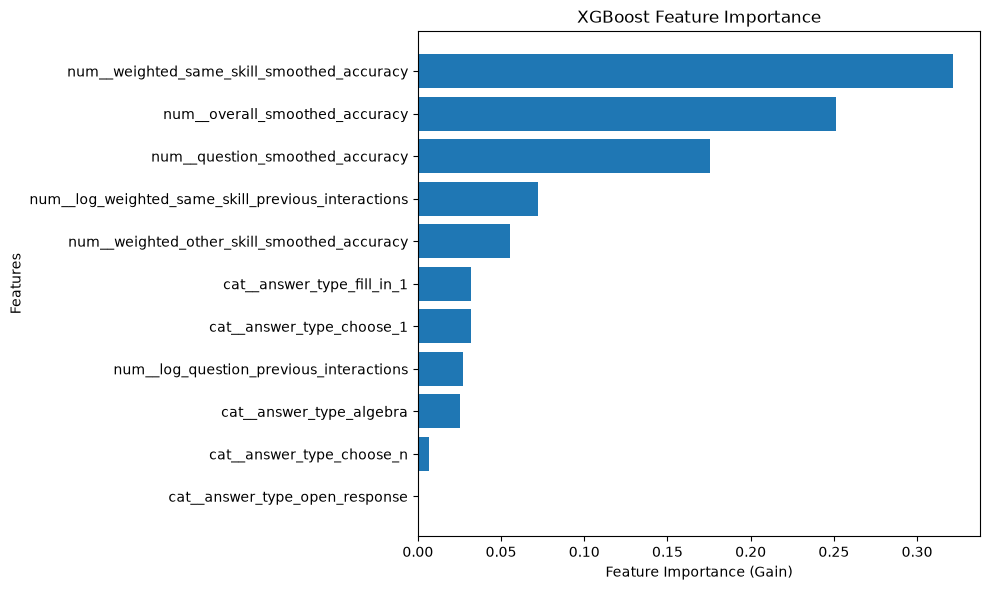

In [53]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["feature"],
    feature_importance["importance"]
)

plt.xlabel("Feature Importance (Gain)")
plt.ylabel("Features")
plt.title("XGBoost Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

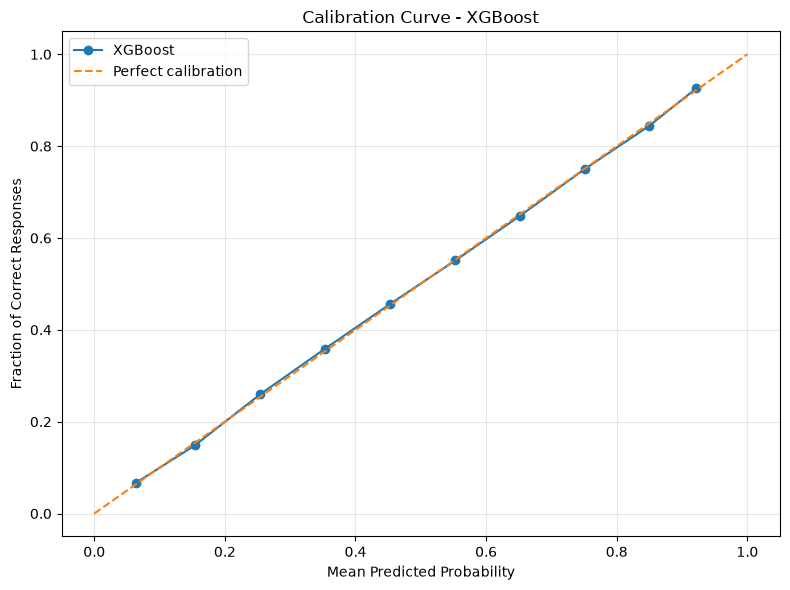

In [54]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# Calculate observed accuracy and predicted probability
fraction_of_positives, mean_predicted_value = calibration_curve(
    y_test,
    y_pred_proba,
    n_bins=10,
    strategy="uniform"
)

# Plot calibration curve
plt.figure(figsize=(8, 6))

plt.plot(
    mean_predicted_value,
    fraction_of_positives,
    marker="o",
    label="XGBoost"
)

# Perfect calibration reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Perfect calibration"
)

plt.xlabel("Mean Predicted Probability")
plt.ylabel("Fraction of Correct Responses")
plt.title("Calibration Curve - XGBoost")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [55]:
import os
import joblib

# Create directory for final model artifacts
MODEL_DIR = "models/final"
os.makedirs(MODEL_DIR, exist_ok=True)

# Save complete preprocessing + XGBoost pipeline
model_path = os.path.join(MODEL_DIR, "next_move_xgboost_pipeline.joblib")

joblib.dump(final_pipeline, model_path)

print("Model saved successfully!")
print("Location:", model_path)

Model saved successfully!
Location: models/final\next_move_xgboost_pipeline.joblib


In [56]:
import os
import numpy as np
import pandas as pd

# Create directory for prediction outputs
PREDICTION_DIR = "data/processed/model_predictions"
os.makedirs(PREDICTION_DIR, exist_ok=True)

# Construct test prediction DataFrame
test_predictions = pd.DataFrame({
    "user_id": final_test_features["user_id"].to_numpy(),
    "order_id": final_test_features["order_id"].to_numpy(),
    "actual_correct": np.asarray(y_test),
    "predicted_correct_probability": y_pred_proba,
    "predicted_incorrect_probability": risk_proba,
    "predicted_risk": (risk_proba >= FINAL_THRESHOLD).astype(int)
})

# Save predictions
prediction_path = os.path.join(
    PREDICTION_DIR,
    "xgboost_test_predictions.csv"
)

test_predictions.to_csv(prediction_path, index=False)

print("Test predictions saved successfully!")
print("Location:", prediction_path)
print("Shape:", test_predictions.shape)
print("\nPreview:")
display(test_predictions.head())

Test predictions saved successfully!
Location: data/processed/model_predictions\xgboost_test_predictions.csv
Shape: (55475, 6)

Preview:


,user_id,order_id,actual_correct,predicted_correct_probability,predicted_incorrect_probability,predicted_risk
0,54318,28025073,0,0.433341,0.566659,1
1,54318,28025127,1,0.369625,0.630375,1
2,54318,28025188,0,0.569740,0.430260,1
3,54318,28025226,1,0.514647,0.485353,1
4,54318,28025243,1,0.389213,0.610787,1


In [57]:
import json

final_results = {
    "model": FINAL_MODEL,
    "random_state": RANDOM_STATE,
    "threshold": FINAL_THRESHOLD,
    "target_recall": TARGET_RECALL,

    "test_metrics": {
        "log_loss": 0.549723,
        "brier_score": 0.184909,
        "roc_auc": 0.746778,
        "average_precision_risk": 0.624092
    },

    "risk_classification": {
        "precision": 0.4946,
        "recall": 0.7472,
        "f1_score": 0.5952,
        "specificity": 0.6021,
        "true_negatives": 21956,
        "false_positives": 14511,
        "false_negatives": 4805,
        "true_positives": 14203,
        "flagged_interactions": 28714
    },

    "dataset": {
        "training_interactions": 219983,
        "test_interactions": 55475,
        "training_students": 3373,
        "test_students": 844
    },

    "features": feature_columns,
    "transformed_feature_count": 11,
    "xgboost_parameters": FINAL_XGB_PARAMS
}

metrics_path = os.path.join(
    MODEL_DIR,
    "final_evaluation_metrics.json"
)

with open(metrics_path, "w") as f:
    json.dump(final_results, f, indent=4)

print("Evaluation metrics saved successfully!")
print("Location:", metrics_path)

Evaluation metrics saved successfully!
Location: models/final\final_evaluation_metrics.json


In [58]:
import os

artifact_paths = [
    "models/final/next_move_xgboost_pipeline.joblib",
    "models/final/final_evaluation_metrics.json",
    "data/processed/model_predictions/xgboost_test_predictions.csv"
]

for path in artifact_paths:
    if os.path.exists(path):
        print(f"FOUND   : {path} ({os.path.getsize(path) / 1024:.2f} KB)")
    else:
        print(f"MISSING : {path}")

FOUND   : models/final/next_move_xgboost_pipeline.joblib (1268.82 KB)
FOUND   : models/final/final_evaluation_metrics.json (1.48 KB)
FOUND   : data/processed/model_predictions/xgboost_test_predictions.csv (2228.48 KB)
